# Etapa 3b — Pronóstico del rinde por campaña (H3): ARIMA, ARIMAX, Prophet e híbridos ARIMA + ML

**H3:** agregar el ONI de jul–sep (conocido al sembrar) como variable exógena reduce el error de pronóstico fuera de
muestra frente al mejor modelo univariado. *H0: igual precisión (Diebold-Mariano).*

**Diseño**
- Rinde pampeano 1970/71–2024/25, modelado en logaritmo. Así la tendencia tecnológica es multiplicativa y los efectos quedan en %.
- **Origen móvil:** se pronostica cada campaña de 1995/96 a 2024/25 (30 pronósticos) con datos solo hasta la anterior.
  Cada modelo se reajusta en cada origen y su orden se elige ahí mismo, así que no hay *look-ahead*.
- Información disponible al sembrar: el ONI de jul–sep y los índices SOI e IOD de jul–sep del año de siembra.

| # | Modelo | Clase |
|---|---|---|
| M0 | Naive (rinde de la campaña anterior) | 11 |
| M1 | Tendencia lineal (`tslm`) | 11 |
| M2 | ARIMA(p,1,q) con drift, orden por AICc | 11 |
| M3 | **ARIMAX** = M2 + ONI jul–sep | 11 |
| M4 | ARIMAX + ONI dic–feb (*oráculo*: no se conoce al sembrar; es la cota superior) | 11 |
| M5 | Prophet con regresor ONI jul–sep | 12 |
| M6–M9 | **Híbrido**: ARIMA para la tendencia + ML (Ridge, Random Forest, Gradient Boosting, MLP) sobre el residuo, con variables ENSO | 12 / ML |

**Por qué híbrido y no ML puro:** con unas 50 campañas, un modelo de árboles sobre el rinde en nivel no puede
extrapolar la tendencia tecnológica (siempre predice dentro del rango visto). El ARIMA se ocupa de la tendencia
y el ML solo aprende la parte climática, que es estacionaria (Etapa 1).

In [1]:
import json
import logging
import os
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from prophet import Prophet
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.stattools import durbin_watson
from statsmodels.tsa.arima.model import ARIMA

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))
from utils_ts import (COLOR, CULTIVO_COLOR, CULTIVO_NOMBRE, adf_kpss, dm_test, estilo, metricas,
                      oni_campanias, rindes)

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
logging.getLogger("prophet").setLevel(logging.ERROR)
estilo()
PROC, FIG, RES = RAIZ / "data" / "processed", RAIZ / os.environ.get("FIG_DIR", "figures"), RAIZ / "results"
FIG.mkdir(exist_ok=True, parents=True)
enso = pd.read_parquet(PROC / "enso_mensual.parquet")
rend = pd.read_parquet(PROC / "rendimientos_anuales.parquet")
camp = pd.read_parquet(PROC / "campanias.parquet")

Y = rindes(rend)
O = oni_campanias(camp)
jas = lambda col: enso[col].groupby(enso.index.year).apply(lambda s: s[s.index.month.isin([7, 8, 9])].mean())
# ONI de un trimestre = valor asignado a su mes central (JAS -> agosto, AMJ -> mayo, DJF -> enero del año siguiente).
# Se toma de la serie mensual (no de la tabla de campañas) para incluir 2025 y 2026, que todavía no tienen rinde.
oni_mes = lambda mes, desfase=0: enso["oni"][enso.index.month == mes].set_axis(enso.index[enso.index.month == mes].year - desfase)
X = pd.DataFrame({
    "oni_jas": oni_mes(8),
    "oni_tend": oni_mes(8) - oni_mes(5),               # ¿el ENSO se está intensificando o decayendo?
    "soi_jas": jas("soi"),
    "iod_jas": jas("iod"),
    "oni_djf": oni_mes(1, desfase=1),                  # solo para el oráculo M4
}).loc[1960:2026]
assert np.allclose(X.loc[1970:2024, "oni_jas"], O.loc[1970:2024, "oni_JAS_0"])
print(X.loc[[1988, 1997, 2008, 2015, 2022, 2025, 2026]].round(2).to_string())
TEST = range(1995, 2025)
CULTIVOS = ["soja", "maiz", "trigo"]

Importing plotly failed. Interactive plots will not work.


       oni_jas  oni_tend  soi_jas  iod_jas  oni_djf
fecha                                              
1988     -1.14     -0.15     1.43    -0.28    -1.64
1997      1.79      1.08    -1.20     0.62     2.22
2008     -0.20      0.65     0.83     0.15    -0.89
2015      1.73      0.69    -1.37     0.36     2.50
2022     -0.78      0.05     1.13    -0.25    -0.55
2025     -0.26     -0.22     0.33    -0.32    -0.39
2026      2.16      1.21    -1.75      NaN      NaN


## 1. Análisis previo de la Clase 11: tendencia lineal, Durbin-Watson y ACF/PACF de Δlog

In [2]:
for c in CULTIVOS:
    ly = np.log(Y[c])
    r = smf.ols("ly ~ t", pd.DataFrame({"ly": ly, "t": ly.index})).fit()
    print(f"{c:6s} tslm: crecimiento {100 * r.params['t']:.2f} %/año · R² {r.rsquared:.2f} · "
          f"Durbin-Watson {durbin_watson(r.resid):.2f} · Δlog: {adf_kpss(ly.diff())['decisión']}")

soja   tslm: crecimiento 1.10 %/año · R² 0.52 · Durbin-Watson 2.00 · Δlog: estacionaria
maiz   tslm: crecimiento 2.22 %/año · R² 0.82 · Durbin-Watson 1.30 · Δlog: estacionaria
trigo  tslm: crecimiento 1.65 %/año · R² 0.81 · Durbin-Watson 1.81 · Δlog: estacionaria


In [3]:
def aicc(res):
    k = len(res.params)
    return res.aic + 2 * k * (k + 1) / max(res.nobs - k - 1, 1)


def arima_auto(ly, exog=None):
    """auto.arima reducido: (p,1,q) con drift, p,q ∈ {0,1,2}, mínimo AICc."""
    mejor = None
    for p in range(3):
        for q in range(3):
            try:
                r = ARIMA(ly, exog=exog, order=(p, 1, q), trend="t").fit()
            except Exception:
                continue
            if mejor is None or aicc(r) < aicc(mejor[1]):
                mejor = ((p, 1, q), r)
    return mejor


for c in CULTIVOS:
    ly = np.log(Y[c]).reset_index(drop=True)
    orden, r = arima_auto(ly)
    print(f"{c:6s} muestra completa: ARIMA{orden} con drift · AICc {aicc(r):.1f}")

soja   muestra completa: ARIMA(0, 1, 1) con drift · AICc -28.0
maiz   muestra completa: ARIMA(0, 1, 1) con drift · AICc -41.5


trigo  muestra completa: ARIMA(0, 1, 1) con drift · AICc -59.9


## 2. Origen móvil 1995/96–2024/25

In [4]:
def hibrido_features(anios):
    return X.loc[anios, ["oni_jas", "oni_tend", "soi_jas", "iod_jas"]].to_numpy()


def modelos_ml():
    return {
        "Híbrido Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30), cv=TimeSeriesSplit(4))),
        "Híbrido RF": RandomForestRegressor(n_estimators=400, max_depth=3, min_samples_leaf=4, random_state=0),
        "Híbrido GBM": GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.03, subsample=0.8,
                                                 min_samples_leaf=4, random_state=0),
        "Híbrido MLP": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(8,), alpha=3.0, solver="lbfgs",
                                                                     max_iter=5000, random_state=0)),
    }


def pronosticar(c):
    ly_all = np.log(Y[c])
    filas = []
    for t in TEST:
        tr = ly_all.loc[:t - 1]
        anios = tr.index
        ly = tr.reset_index(drop=True)
        f = {"campania": t, "obs": Y.loc[t, c]}
        f["M0 Naive"] = np.exp(ly.iloc[-1])
        b = np.polyfit(anios, ly, 1)
        f["M1 Tendencia lineal"] = np.exp(np.polyval(b, t))
        orden, r2 = arima_auto(ly)
        f["M2 ARIMA"] = np.exp(r2.forecast(1).iloc[0])
        f["orden"] = str(orden)
        for nombre, col in [("M3 ARIMAX (ONI jul–sep)", "oni_jas"), ("M4 ARIMAX oráculo (ONI dic–feb)", "oni_djf")]:
            ex = X.loc[anios, [col]].to_numpy()
            r3 = ARIMA(ly, exog=ex, order=orden, trend="t").fit()
            f[nombre] = np.exp(r3.forecast(1, exog=X.loc[[t], [col]].to_numpy()).iloc[0])
            if col == "oni_jas":
                f["beta_oni"] = r3.params.iloc[1] if len(r3.params) > 1 else np.nan
        # Prophet: tendencia lineal por tramos + regresor ONI (sin estacionalidad: datos anuales)
        dfp = pd.DataFrame({"ds": pd.to_datetime(anios.astype(str)), "y": ly.to_numpy(), "oni": X.loc[anios, "oni_jas"].to_numpy()})
        mp = Prophet(yearly_seasonality=False, weekly_seasonality=False, daily_seasonality=False,
                     changepoint_prior_scale=0.05, uncertainty_samples=0)
        mp.add_regressor("oni")
        mp.fit(dfp)
        f["M5 Prophet + ONI"] = np.exp(mp.predict(pd.DataFrame({"ds": [pd.Timestamp(f"{t}")], "oni": [X.loc[t, "oni_jas"]]}))["yhat"].iloc[0])
        # Híbridos: el ML aprende el residuo un paso adelante del ARIMA dentro del entrenamiento
        resid = r2.resid.iloc[1:].to_numpy()
        Xr = hibrido_features(anios[1:])
        for nombre, mod in modelos_ml().items():
            mod.fit(Xr, resid)
            f[nombre] = f["M2 ARIMA"] * np.exp(mod.predict(hibrido_features([t]))[0])
        filas.append(f)
    return pd.DataFrame(filas).set_index("campania")


t0 = time.time()
P = {}
for c in CULTIVOS:
    P[c] = pronosticar(c)
    print(f"{c}: {time.time() - t0:.0f} s · órdenes elegidos: {P[c]['orden'].value_counts().to_dict()}")

19:01:09 - cmdstanpy - INFO - Chain [1] start processing


19:01:09 - cmdstanpy - INFO - Chain [1] done processing


19:01:10 - cmdstanpy - INFO - Chain [1] start processing


19:01:10 - cmdstanpy - INFO - Chain [1] done processing


19:01:10 - cmdstanpy - INFO - Chain [1] start processing


...

19:01:57 - cmdstanpy - INFO - Chain [1] start processing


19:01:57 - cmdstanpy - INFO - Chain [1] done processing


19:01:57 - cmdstanpy - INFO - Chain [1] start processing


19:01:57 - cmdstanpy - INFO - Chain [1] done processing


trigo: 49 s · órdenes elegidos: {'(0, 1, 1)': 26, '(0, 1, 2)': 3, '(2, 1, 1)': 1}


In [5]:
MODELOS = ["M0 Naive", "M1 Tendencia lineal", "M2 ARIMA", "M3 ARIMAX (ONI jul–sep)", "M4 ARIMAX oráculo (ONI dic–feb)",
           "M5 Prophet + ONI", "Híbrido Ridge", "Híbrido RF", "Híbrido GBM", "Híbrido MLP"]
nina = X.loc[list(TEST), "oni_jas"] <= -0.5
tabla, dmt = [], []
for c in CULTIVOS:
    p = P[c]
    mse_ref = np.mean((p.obs - p["M2 ARIMA"]) ** 2)
    for mdl in MODELOS:
        e = p.obs - p[mdl]
        tabla.append({"cultivo": c, "modelo": mdl, "RMSE kg/ha": np.sqrt(np.mean(e ** 2)), "MAE kg/ha": np.mean(np.abs(e)),
                      "MAPE %": 100 * np.mean(np.abs(e / p.obs)), "skill vs ARIMA %": 100 * (1 - np.mean(e ** 2) / mse_ref),
                      "RMSE años Niña": np.sqrt(np.mean(e[nina.to_numpy()] ** 2))})
        if mdl != "M2 ARIMA":
            r = dm_test(np.log(p.obs) - np.log(p[mdl]), np.log(p.obs) - np.log(p["M2 ARIMA"]), h=1, alternativa="less")
            dmt.append({"cultivo": c, "modelo vs M2 ARIMA": mdl, "DM": r["DM"], "p (1 cola)": r["p"]})
tabla, dmt = pd.DataFrame(tabla), pd.DataFrame(dmt)
for c in CULTIVOS:
    print(f"\n=== {CULTIVO_NOMBRE[c]} (n = {len(TEST)} pronósticos, {nina.sum()} campañas Niña) ===")
    print(tabla[tabla.cultivo == c].drop(columns="cultivo").set_index("modelo").round(1).to_string())
print("\nDiebold-Mariano (H1: el modelo tiene menor error que M2 ARIMA), pérdida cuadrática en log:")
print(dmt.pivot(index="modelo vs M2 ARIMA", columns="cultivo", values="p (1 cola)").loc[[m for m in MODELOS if m != "M2 ARIMA"], CULTIVOS].round(3).to_string())


=== Soja (n = 30 pronósticos, 7 campañas Niña) ===
                                 RMSE kg/ha  MAE kg/ha  MAPE %  skill vs ARIMA %  RMSE años Niña
modelo                                                                                          
M0 Naive                              595.2      445.7    17.7             -75.0           461.5
M1 Tendencia lineal                   444.0      315.3    13.8               2.6           595.8
M2 ARIMA                              449.9      319.9    14.0               0.0           595.7
M3 ARIMAX (ONI jul–sep)               409.7      310.8    13.3              17.1           540.1
M4 ARIMAX oráculo (ONI dic–feb)       406.0      301.6    13.0              18.5           580.1
M5 Prophet + ONI                      419.0      331.3    14.0              13.3           543.5
Híbrido Ridge                         452.8      335.7    14.6              -1.3           589.7
Híbrido RF                            403.7      322.0    13.5             

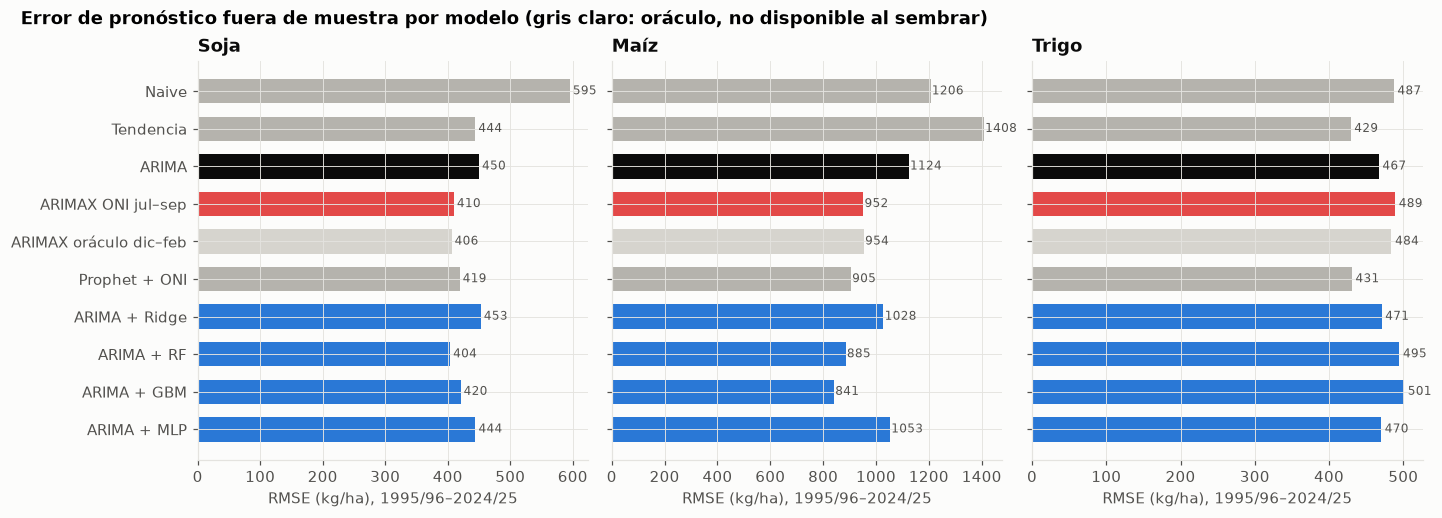

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.6), sharey=False)
cortos = {"M0 Naive": "Naive", "M1 Tendencia lineal": "Tendencia", "M2 ARIMA": "ARIMA", "M3 ARIMAX (ONI jul–sep)": "ARIMAX ONI jul–sep",
          "M4 ARIMAX oráculo (ONI dic–feb)": "ARIMAX oráculo dic–feb", "M5 Prophet + ONI": "Prophet + ONI",
          "Híbrido Ridge": "ARIMA + Ridge", "Híbrido RF": "ARIMA + RF", "Híbrido GBM": "ARIMA + GBM", "Híbrido MLP": "ARIMA + MLP"}
for ax, c in zip(axs, CULTIVOS):
    t_ = tabla[tabla.cultivo == c].set_index("modelo").loc[MODELOS]
    colores = [COLOR["nino"] if m.startswith("M3") else (COLOR["tinta"] if m == "M2 ARIMA" else
               ("#d6d4ce" if "oráculo" in m else COLOR["serie"] if m.startswith("Híbrido") else COLOR["neutral"])) for m in MODELOS]
    ax.barh(range(len(MODELOS)), t_["RMSE kg/ha"], color=colores, height=0.65)
    for i, v in enumerate(t_["RMSE kg/ha"]):
        ax.text(v + 5, i, f"{v:.0f}", va="center", fontsize=8, color=COLOR["tinta2"])
    ax.set_yticks(range(len(MODELOS)), [cortos[m] for m in MODELOS] if c == "soja" else [""] * len(MODELOS))
    ax.invert_yaxis()
    ax.set_title(f"{CULTIVO_NOMBRE[c]}")
    ax.set_xlabel("RMSE (kg/ha), 1995/96–2024/25")
fig.suptitle("Error de pronóstico fuera de muestra por modelo (gris claro: oráculo, no disponible al sembrar)",
             x=0.01, ha="left", fontweight="bold")
fig.savefig(FIG / "15_rmse_modelos_rindes.png")
plt.show()

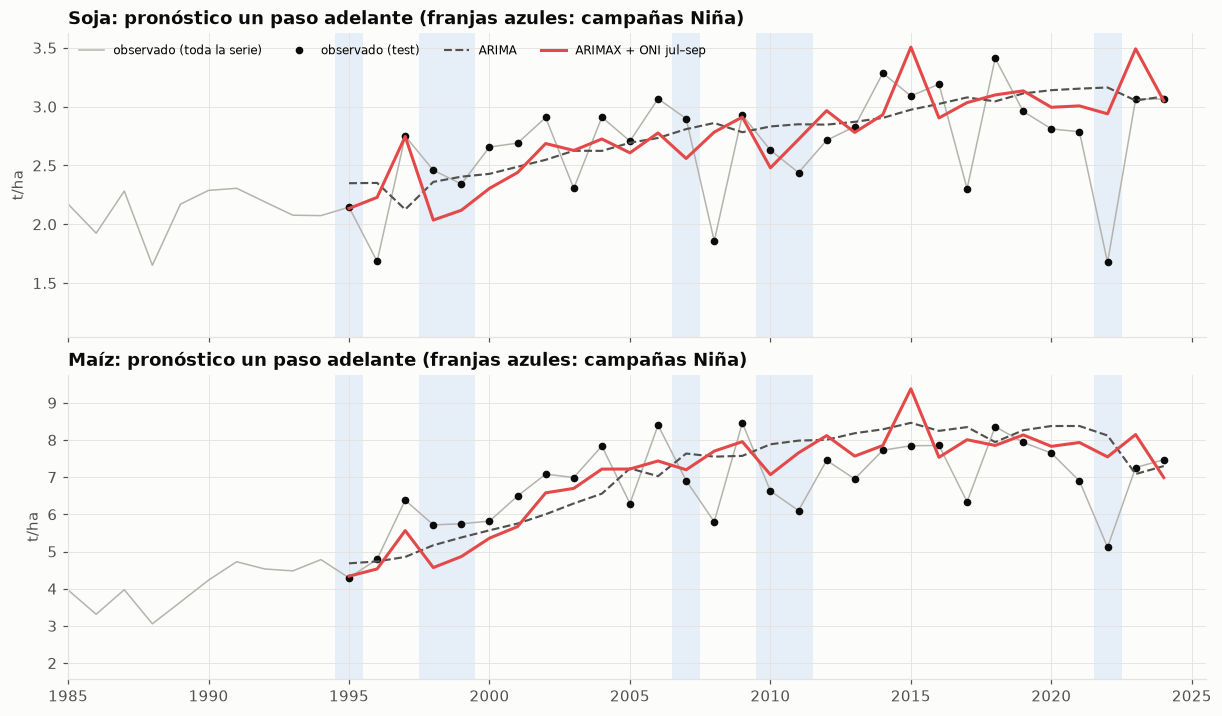

In [7]:
fig, axs = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
for ax, c in zip(axs, ["soja", "maiz"]):
    p = P[c]
    ax.plot(Y.index, Y[c] / 1000, color=COLOR["neutral"], lw=1, label="observado (toda la serie)")
    ax.plot(p.index, p.obs / 1000, color=COLOR["tinta"], lw=0, marker="o", ms=4, label="observado (test)")
    ax.plot(p.index, p["M2 ARIMA"] / 1000, color=COLOR["tinta2"], lw=1.4, ls="--", label="ARIMA")
    ax.plot(p.index, p["M3 ARIMAX (ONI jul–sep)"] / 1000, color=COLOR["nino"], lw=2, label="ARIMAX + ONI jul–sep")
    for a in p.index[nina.to_numpy()]:
        ax.axvspan(a - 0.5, a + 0.5, color=COLOR["nina"], alpha=0.10, lw=0)
    ax.set_ylabel("t/ha")
    ax.set_title(f"{CULTIVO_NOMBRE[c]}: pronóstico un paso adelante (franjas azules: campañas Niña)")
axs[0].legend(fontsize=8, ncol=4, loc="upper left")
axs[1].set_xlim(1985, 2025.5)
fig.savefig(FIG / "16_pronosticos_rindes.png")
plt.show()

## 3. Pronóstico de las campañas 2025/26 y 2026/27

Se usa el ARIMAX ajustado con toda la serie (hasta 2024/25). Las exógenas son el ONI de jul–sep de 2025 (ya observado)
y el de jul–sep de 2026 (+2,16 °C). **Ojo:** +2,16 está **en el borde o por fuera del rango histórico** de ONI de jul–sep,
así que el pronóstico extrapola la relación lineal. Por eso se presenta con intervalos y se compara con el ARIMA sin ENSO.

In [8]:
print(f"ONI jul–sep: máximo histórico 1970–2024 = {X.loc[1970:2024, 'oni_jas'].max():.2f} ({X.loc[1970:2024, 'oni_jas'].idxmax()}) · 2026 = {X.loc[2026, 'oni_jas']:.2f}")
pron_fut = []
for c in ["soja", "maiz"]:
    ly = np.log(Y[c]).reset_index(drop=True)
    orden, r2 = arima_auto(ly)
    ex = X.loc[Y.index, ["oni_jas"]].to_numpy()
    r3 = ARIMA(ly, exog=ex, order=orden, trend="t").fit()
    fx = r3.get_forecast(2, exog=X.loc[[2025, 2026], ["oni_jas"]].to_numpy())
    f2 = r2.get_forecast(2)
    for k, anio in enumerate([2025, 2026]):
        i80, i95 = np.exp(fx.conf_int(alpha=0.2).iloc[k]), np.exp(fx.conf_int(alpha=0.05).iloc[k])
        pron_fut.append({"cultivo": c, "campaña": f"{anio}/{str(anio + 1)[-2:]}", "ONI jul–sep": X.loc[anio, "oni_jas"],
                         "ARIMA kg/ha": np.exp(f2.predicted_mean.iloc[k]), "ARIMAX kg/ha": np.exp(fx.predicted_mean.iloc[k]),
                         "IC80": f"{i80.iloc[0]:.0f}–{i80.iloc[1]:.0f}", "IC95": f"{i95.iloc[0]:.0f}–{i95.iloc[1]:.0f}",
                         "β ONI (%/°C)": 100 * r3.params.iloc[1]})
pron_fut = pd.DataFrame(pron_fut)
pron_fut["efecto ENSO %"] = 100 * (pron_fut["ARIMAX kg/ha"] / pron_fut["ARIMA kg/ha"] - 1)
print(pron_fut.round(1).to_string(index=False))

ONI jul–sep: máximo histórico 1970–2024 = 1.79 (1997) · 2026 = 2.16


cultivo campaña  ONI jul–sep  ARIMA kg/ha  ARIMAX kg/ha       IC80       IC95  β ONI (%/°C)  efecto ENSO %
   soja 2025/26         -0.3       3119.0        3015.6  2470–3682  2222–4092          10.1           -3.3
   soja 2026/27          2.2       3153.4        3887.2  3184–4746  2865–5275          10.1           23.3
   maiz 2025/26         -0.3       7503.2        7168.5  6017–8541  5484–9371           9.1           -4.5
   maiz 2026/27          2.2       7654.1        9095.5 7562–10940 6858–12063           9.1           18.8


In [9]:
salida = {"tabla": tabla.round(3).to_dict("records"), "dm": dmt.round(4).to_dict("records"),
          "pronostico_futuro": pron_fut.round(2).to_dict("records")}
(RES / "etapa3b_rindes.json").write_text(json.dumps(salida, indent=2, default=float, ensure_ascii=False))
for c in CULTIVOS:
    P[c].to_csv(RES / f"pronosticos_rolling_{c}.csv")

## 4. Conclusiones (H3)

- **Clase 11:** el ARIMA elegido por AICc es casi siempre (0,1,1) con drift, que equivale a un suavizado exponencial
  con tendencia. La tendencia lineal (`tslm`) en maíz deja residuos autocorrelacionados (DW = 1,30), porque su
  tendencia se aplana desde 2015.
- **Maíz:** agregar el ONI de jul–sep reduce el RMSE fuera de muestra un 28 % (de 1.124 a 952 kg/ha; DM p = 0,043).
  Los modelos no lineales sobre el residuo mejoran más: ARIMA + GBM −25 % de RMSE (skill 44 %) y ARIMA + RF skill 38 %.
  El mayor beneficio está en los años Niña.
- **Soja:** ARIMAX skill 17 % (DM p = 0,097). ARIMA + RF skill 20 %, y en años Niña baja el RMSE de 596 a 425 kg/ha.
  La evidencia a favor de H3 es marginal: la soja tiene más ruido no climático (por ejemplo, el área de soja de segunda).
- **Trigo (contraste):** ningún modelo con ENSO mejora al ARIMA, coherente con las Etapas 1 y 2.
- El **oráculo** (ONI dic–feb, que se conoce recién al final del ciclo) **no supera** al ONI de jul–sep. La información
  útil ya está disponible al sembrar.
- **Con Holm** sobre soja y maíz, el ARIMAX queda en p = 0,086 y 0,097. Es honesto decir que H3 está
  **parcialmente** sostenida: hay una mejora consistente en magnitud y significativa sin corregir para maíz.
- **Ridge y MLP** sobre el residuo mejoran poco: nada en soja y entre 12 y 16 % en maíz. Con unas 50 campañas y 4 variables,
  la regularización los acerca al ARIMA. Los árboles poco profundos capturan mejor la asimetría: La Niña daña más de lo que El Niño suma.
- **Pronóstico 2026/27** (ARIMAX con ONI jul–sep = +2,16):
  - Soja: unos 3.900 kg/ha (IC80 3.200–4.700), +23 % sobre el ARIMA sin ENSO.
  - Maíz: unos 9.100 kg/ha (IC80 7.600–10.900), +19 %.
  - **Advertencia:** +2,16 está por encima del máximo histórico de jul–sep (1,79 en 1997), así que se extrapola una relación lineal.
    En años muy Niño puede haber excesos hídricos que no captura un efecto lineal.